In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

from experiments_utils import RESULTS_DIR

In [ ]:
ICS26_DIR = RESULTS_DIR / "ics26"
for d in ICS26_DIR.iterdir():
    print(d.name)

ics_quadratic
ics_shifted_gaussians
ics_rosenbrock


In [ ]:
# Publication-Quality Plot Settings
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.figsize": (6.5, 4.5),
        "figure.dpi": 100,
        "savefig.dpi": 300,
        "lines.linewidth": 1.5,
        "lines.markersize": 5,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.axisbelow": True,
    }
)
PALETTE = "deep"
COLORS = sns.color_palette(PALETTE)

In [ ]:
def plot_error_with_log_log_fit(
    df,
    error_col1,
    error_col2,
    title1,
    title2,
    error_metric_col="ERROR_METRIC",
    skip_first_n=0,
):
    # drop rows where error_col1 or error_col2 is  or zero
    df = df[(df[error_col1] > 0) & (df[error_col2] > 0)]
    plt.figure(figsize=(16, 6))
    plt.subplot(1, 2, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col1,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col1].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
            plt.plot(
                np.exp(x_fit), np.exp(y_fit), linestyle="--", color="k", label=label
            )
        plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col1.replace("_", " ").title())
    plt.title(title1)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 2, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y=error_col2,
        hue="dim",
        style=error_metric_col,
        marker="o",
        palette=PALETTE,
    )
    for dim in df["dim"].unique():
        for e in df[error_metric_col].unique():
            subset = df[(df["dim"] == dim) & (df[error_metric_col] == e)]
            if len(subset) <= 1:
                continue
            X = np.log(subset["n_clusters"].values).reshape(-1, 1)
            y = np.log(subset[error_col2].values)
            if skip_first_n > 0:
                X = X[skip_first_n:]
                y = y[skip_first_n:]
            model = LinearRegression()
            model.fit(X, y)
            x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
            y_fit = model.predict(x_fit.reshape(-1, 1))
            label = rf"$({dim}D) (E={e}) \approx O(n_{{clusters}}^{{{model.coef_[0]:.2f}}})$"
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(error_col2.replace("_", " ").title())
    plt.title(title2)
    plt.legend()
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()


def plot_percentage_metrics(df):
    plt.figure(figsize=(24, 7))
    plt.subplot(1, 3, 1)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_out",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ out (perct_out)")
    plt.title(r"$\%$ out vs Number of Cluster")
    plt.ylim(0, 100)
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 2)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_good",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Good (perct_in_good)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Good vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)

    plt.subplot(1, 3, 3)
    sns.lineplot(
        data=df,
        x="n_clusters",
        y="perct_in_bad",
        hue="dim",
        style="ERROR_METRIC",
        marker="o",
        palette=PALETTE,
    )
    plt.xscale("log")
    plt.xlabel("Number of Clusters (n_clusters)")
    plt.ylabel(r"$\%$ in-Bad (perct_in_bad)")
    plt.ylim(0, 100)
    plt.title(r"$\%$ in-Bad vs Number of Cluster")
    plt.grid(True, which="both", ls="--", lw=0.5)
    plt.show()

# Problems

In [ ]:
prob_dir = ICS26_DIR / "ics_rosenbrock"
csv_path = prob_dir / "summary.csv"

df_problem = pd.read_csv(csv_path)
df_problem = df_problem.dropna(subset=["n_clusters"])

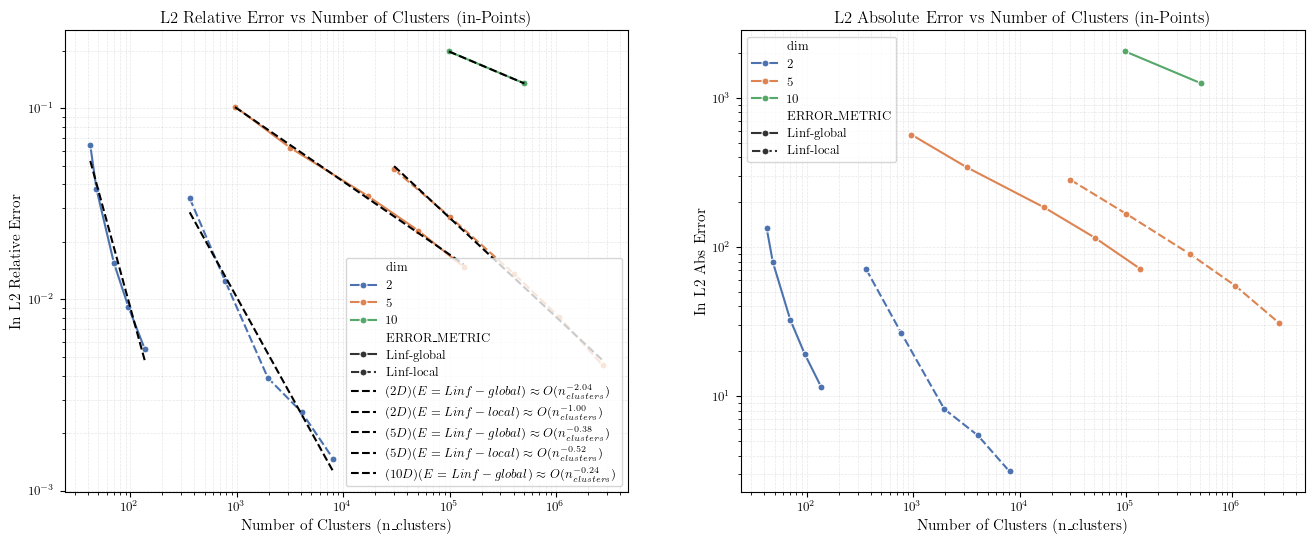

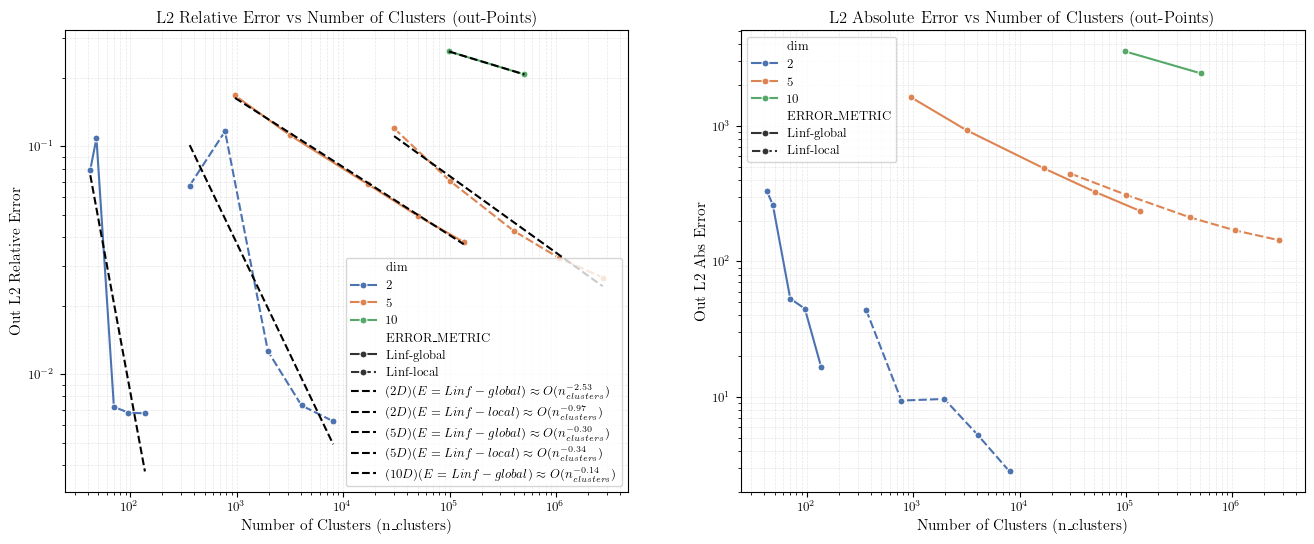

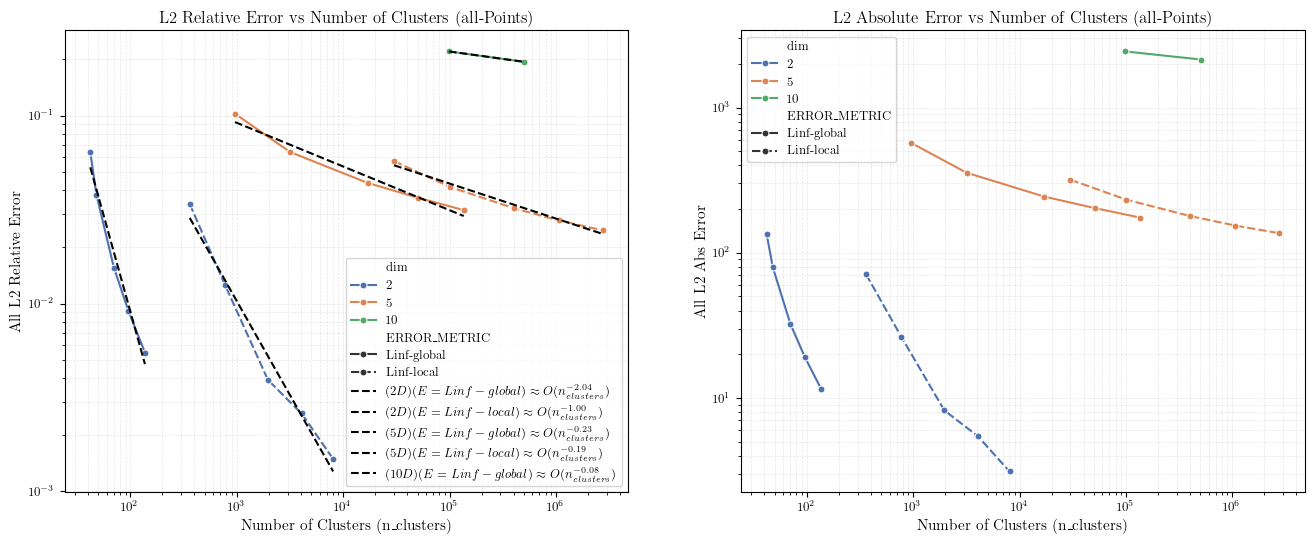

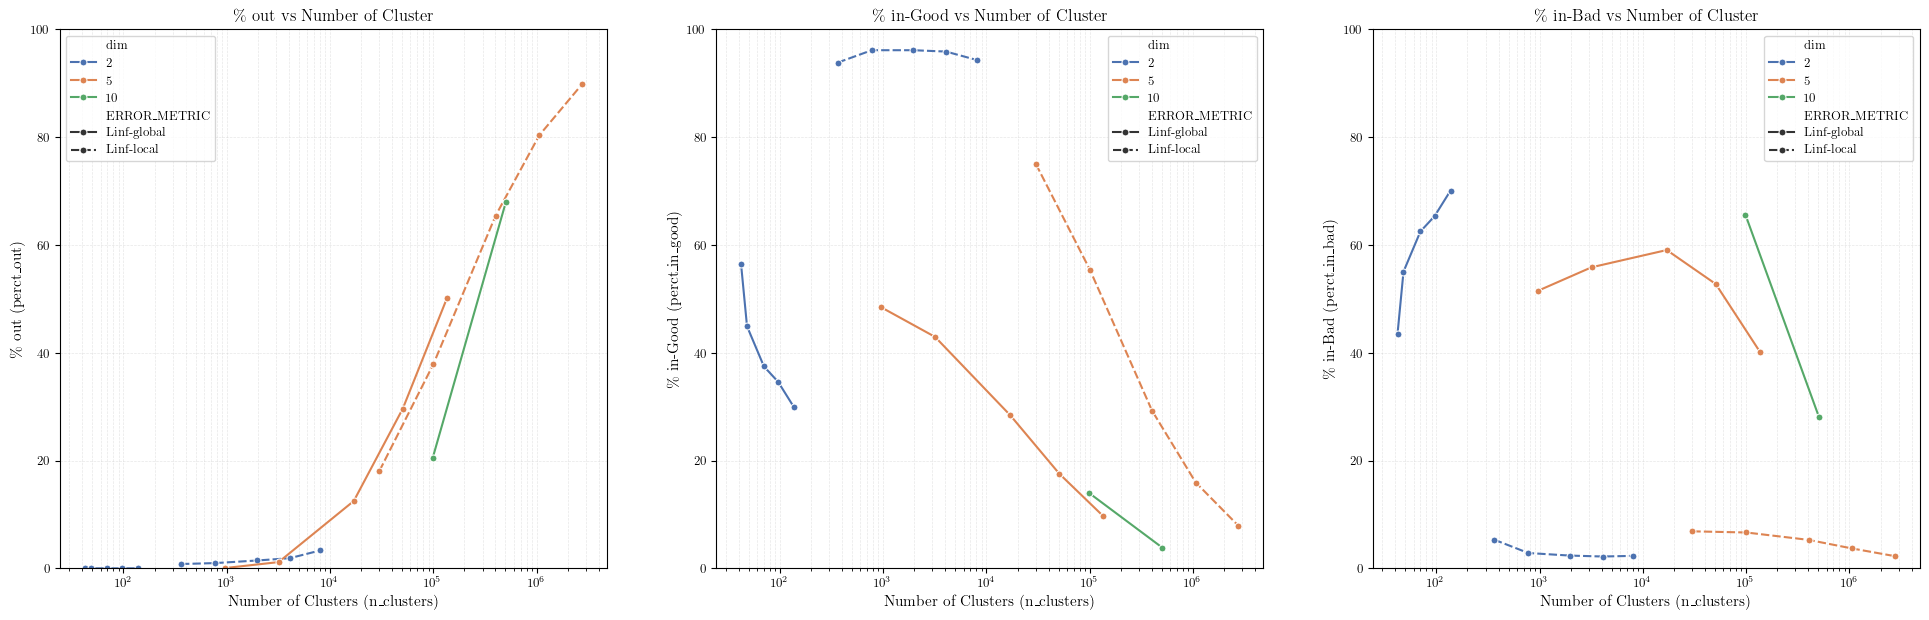

In [ ]:
if "hessian_estimation" in prob_dir.name:
    plot_error_with_log_log_fit(
        df_problem,
        "l2_rel_error",
        "l2_abs_error",
        "L2 Relative Error vs Number of Clusters",
        "L2 Absolute Error vs Number of Clusters",
        error_metric_col="metric",
        skip_first_n=1,
    )
else:
    plot_error_with_log_log_fit(
        df_problem,
        "in_l2_relative_error",
        "in_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (in-Points)",
        "L2 Absolute Error vs Number of Clusters (in-Points)",
    )
    plot_error_with_log_log_fit(
        df_problem,
        "out_l2_relative_error",
        "out_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (out-Points)",
        "L2 Absolute Error vs Number of Clusters (out-Points)",
    )
    plot_error_with_log_log_fit(
        df_problem,
        "all_l2_relative_error",
        "all_l2_abs_error",
        "L2 Relative Error vs Number of Clusters (all-Points)",
        "L2 Absolute Error vs Number of Clusters (all-Points)",
    )
    plot_percentage_metrics(df_problem)

In [ ]:
def get_renamed_df(df):
    rename_cols = {
        "dim": "D",
        "f_dim": "F Dim",
        "tol": "tol",
        "ERROR_METRIC": "Error Metric",
        "n_clusters": "N Src",
        "in_l2_relative_error": "L2 Rel Err (In)",
        "in_l2_abs_error": "L2 Abs Err (In)",
        "in_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (In)",
        "in_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (In)",
        "out_l2_relative_error": "L2 Rel Err (Out)",
        "out_l2_abs_error": "L2 Abs Err (Out)",
        "out_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (Out)",
        "out_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (Out)",
        "perct_out": "% Out",
        "perct_in_good": "% In-Good",
        "perct_in_bad": "% In-Bad",
        "n_out": "N Out",
        "all_l2_relative_error": "L2 Rel Err (All)",
        "all_l2_abs_error": "L2 Abs Err (All)",
        "all_ptwise_max_rel_error_linf": "Ptwise Max Rel L-inf Err (All)",
        "all_ptwise_median_rel_error_linf": "Ptwise Median Rel L-inf Err (All)",
        "N_INIT_CLUSTERS": "Init Clusters",
        "N_MIN_PER_CLUSTER": "Min Per Cluster",
        "n_train": "N Train",
        "n_test": "N Test",
        "num_generated_pts": "N Generated Pts",
        "total_f_evals": "Total F Evals",
    }
    df_renamed = df.rename(columns=rename_cols)[list(rename_cols.values())]
    return df_renamed


# if "hessian_estimation" in prob_dir.name:
display(get_renamed_df(df_problem))
get_renamed_df(df_problem).to_clipboard(index=False)

,D,F Dim,tol,Error Metric,N Src,L2 Rel Err (In),L2 Abs Err (In),Ptwise Max Rel L-inf Err (In),Ptwise Median Rel L-inf Err (In),L2 Rel Err (Out),...,L2 Rel Err (All),L2 Abs Err (All),Ptwise Max Rel L-inf Err (All),Ptwise Median Rel L-inf Err (All),Init Clusters,Min Per Cluster,N Train,N Test,N Generated Pts,Total F Evals
0,2,1,0.100,Linf-global,42,0.063899,133.955551,1172.103922,0.076830,0.079163,...,0.063913,134.029961,1172.103922,0.076845,42,169,84500,42250,0,84542
1,2,1,0.100,Linf-local,361,0.033823,71.192961,44.241890,0.019849,0.067355,...,0.033863,71.012774,44.241890,0.020045,42,169,84500,42250,31772,116952
2,2,1,0.050,Linf-global,48,0.037813,79.293856,1172.103922,0.064160,0.108583,...,0.037852,79.377434,1172.103922,0.064173,42,169,84500,42250,0,84554
3,2,1,0.050,Linf-local,776,0.012533,26.414535,7.603964,0.008658,0.116578,...,0.012541,26.299901,7.603964,0.008780,42,169,84500,42250,87609,173619
4,2,1,0.020,Linf-local,1962,0.003888,8.204953,4.105088,0.003560,0.012627,...,0.003924,8.228291,4.677633,0.003632,42,169,84500,42250,268968,357350
5,2,1,0.020,Linf-global,70,0.015538,32.557752,1172.103922,0.038549,0.007197,...,0.015527,32.561599,1172.103922,0.038547,42,169,84500,42250,0,84598
6,2,1,0.010,Linf-global,96,0.009114,19.096428,2503.731357,0.024977,0.006786,...,0.009110,19.104589,2503.731357,0.024975,42,169,84500,42250,0,84650
7,2,1,0.010,Linf-local,4063,0.002579,5.454027,3.609607,0.001854,0.007300,...,0.002599,5.449776,21.441214,0.001902,42,169,84500,42250,612456,705040
8,2,1,0.005,Linf-global,137,0.005481,11.494548,545.932651,0.015916,0.006742,...,0.005482,11.495846,545.932651,0.015912,42,169,84500,42250,0,84732
9,2,1,0.005,Linf-local,8051,0.001469,3.131891,4.606846,0.000968,0.006224,...,0.001489,3.121952,9.366609,0.001011,42,169,84500,42250,1280591,1381151


In [56]:
error_cols = [
    "in_l2_relative_error",
    "in_l2_abs_error",
    "in_ptwise_max_rel_error_linf",
    "in_ptwise_median_rel_error_linf",
    "out_l2_relative_error",
    "out_l2_abs_error",
    "out_ptwise_max_rel_error_linf",
    "out_ptwise_median_rel_error_linf",
    "all_l2_relative_error",
    "all_l2_abs_error",
    "all_ptwise_max_rel_error_linf",
    "all_ptwise_median_rel_error_linf",
]

results_list = []
for dim in df_problem["dim"].unique():
    for error_metric in df_problem["ERROR_METRIC"].unique():
        subset = df_problem[
            (df_problem["dim"] == dim) & (df_problem["ERROR_METRIC"] == error_metric)
        ]

        # Skip if not enough points to fit a line
        if len(subset) <= 1:
            print(f"Skip: dim={dim}, ERROR_METRIC={error_metric}")
            continue

        # Initialize the row with metadata
        row = {"dim": dim, "ERROR_METRIC": error_metric}
        X = np.log(subset["n_clusters"].values).reshape(-1, 1)

        for error_col in error_cols:
            y = np.log(subset[error_col].values)
            model = LinearRegression()
            model.fit(X, y)
            row[error_col] = model.coef_[0]

        results_list.append(row)


# 1. Create DataFrame directly from the list of dicts
fit_results_df = pd.DataFrame(results_list)

# 2. Set 'dim' and 'ERROR_METRIC' as the index
fit_results_df = fit_results_df.set_index(["dim", "ERROR_METRIC"])

# 3. Transpose (T) to flip rows and columns
final_df = fit_results_df.T

# 4. Rename columns to "2D-metric" format
final_df.columns = [f"{dim}D-{metric}" for dim, metric in final_df.columns]

# --- ADDED: Insert Expected Row ---
# Parse 'D' from column name (e.g., "5D-..." -> 5) and calculate -2/D
expected_values = [-2.0 / int(col.split("D-")[0]) for col in final_df.columns]

# Create the new row
expected_row = pd.DataFrame(
    [expected_values], columns=final_df.columns, index=["Expected"]
)

# Concatenate at the top
final_df = pd.concat([expected_row, final_df])
# ----------------------------------

display(final_df)
final_df.to_clipboard()

Skip: dim=10, ERROR_METRIC=Linf-local


,2D-Linf-global,2D-Linf-local,5D-Linf-global,5D-Linf-local,10D-Linf-global
Expected,-1.000000,-1.000000,-0.400000,-0.400000,-0.200000
in_l2_relative_error,-2.038320,-1.004803,-0.382198,-0.517962,-0.235742
in_l2_abs_error,-2.038397,-1.001262,-0.410823,-0.483156,-0.299790
in_ptwise_max_rel_error_linf,-0.287010,-0.683652,-0.436153,-0.656866,-0.321599
in_ptwise_median_rel_error_linf,-1.337421,-0.964616,-0.374658,-0.573846,-0.233758
out_l2_relative_error,-2.531782,-0.973631,-0.298626,-0.336102,-0.142129
out_l2_abs_error,-2.543426,-0.767910,-0.387907,-0.253816,-0.227521
out_ptwise_max_rel_error_linf,-0.236417,0.407994,0.488929,0.015681,0.176428
out_ptwise_median_rel_error_linf,-2.190734,-1.083722,-0.289469,-0.388925,-0.155730
all_l2_relative_error,-2.038939,-1.000859,-0.232496,-0.186367,-0.078251
